In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import itertools
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_ind_from_stats
from matplotlib.colors import to_rgba

In [ ]:
# HELPER FUNCTIONS

# for time 
def time_to_seconds(t):
    if pd.isna(t):
        return None
    # make sure it's a string
    t = str(t).strip()
    # parse HH:MM:SS (or MM:SS) to seconds
    return pd.to_timedelta(t).total_seconds()

# remove nan values from dfs
# correct pH
def prepare_online_dfs(df, run_name=None):
    dfs = {
        "temp": df[["Age (h)", "TEMP_Value"]].dropna().copy(),
        "pH": df[["Age (h)", "pH_Value"]].dropna().copy(),
        "DO": df[["Age (h)", "pO2_Value"]].dropna().copy(),
        "stirr": df[["Age (h)", "STIRR_Value"]].dropna().copy(),
        "airfl": df[["Age (h)", "AIRFL_Value"]].dropna().copy(),
        "acid": df[["Age (h)", "ACID_Value"]].dropna().copy(),
    }

    acid_df = dfs["acid"]
    pH_df = dfs["pH"]

    if run_name == "run1":
        acid_df.iloc[0:2, acid_df.columns.get_loc("ACID_Value")] = 0.0

    elif run_name == "run2":
        acid_df.iloc[0:2, acid_df.columns.get_loc("ACID_Value")] = 6.0
        acid_df["ACID_Value"] = acid_df["ACID_Value"] - 6.0

        pH_df.loc[:35, "pH_Value"] = 7.02

    elif run_name == "run3":
        acid_df.iloc[0:2, acid_df.columns.get_loc("ACID_Value")] = 14.0
        acid_df["ACID_Value"] = acid_df["ACID_Value"] - 14.0

        pH_df.loc[:5, "pH_Value"] = 7.02

    return dfs

# actual plot
def plot_three_prepared_runs(runs, column_config):
    fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True, constrained_layout=True)

    for ax in axes:
        ax.tick_params(axis='x', labelbottom=True)

    panel_labels = ["[A]", "[B]", "[C]"]

    for idx, (ax, (title, dfs)) in enumerate(zip(axes, runs.items())):
        all_axes = [ax]

        for i, (key, cfg) in enumerate(column_config.items()):
            plot_df = dfs[cfg["df_key"]]

            if i == 0:
                current_ax = ax
                current_ax.set_ylim(6, 10)
            else:
                current_ax = ax.twinx()
                current_ax.spines["right"].set_position(("outward", 60 * (i - 1)))
                all_axes.append(current_ax)

            current_ax.plot(
                plot_df["Age (h)"],
                plot_df[key],
                label=cfg.get("legend", cfg["label"]),
                color=cfg["color"],
                linewidth=1,
            )

            current_ax.set_ylabel(cfg["label"], color=cfg["color"])

            if "yticks" in cfg:
                current_ax.set_yticks(cfg["yticks"])
            
            if "ylim" in cfg:
                current_ax.set_ylim(cfg["ylim"])
            elif "yticks" in cfg:
                current_ax.set_ylim(min(cfg["yticks"]), max(cfg["yticks"]))
            
            current_ax.tick_params(axis="y", colors=cfg["color"])

        ax.set_title(f"{panel_labels[idx]}", loc="left")
        ax.set_xlabel("Time [h]")

        handles, labels = [], []
        for a in all_axes:
            h, l = a.get_legend_handles_labels()
            handles.extend(h)
            labels.extend(l)
    
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=6,
        frameon=False,
        bbox_to_anchor=(0.5, -0.03)
    )

    #plt.savefig("online20L_paper.tiff", dpi=1000, bbox_inches="tight")
    plt.show()

In [ ]:
# load data

# ALE pH7
run1_long = pd.read_excel('ALE7_online_20L_060526.XLS')
run1 = run1_long[run1_long["Age (h)"] <= 24.0]

run2_long = pd.read_excel('ALE7_online2_20L_140526.XLS')
run2 = run2_long[run2_long["Age (h)"] <= 24.0]

run3_long = pd.read_excel('ALE7_online3_20L_140526.XLS')
run3 = run3_long[run3_long["Age (h)"] <= 24.0]

# remove nans
run1_dfs = prepare_online_dfs(run1, "run1")
run2_dfs = prepare_online_dfs(run2, "run2")
run3_dfs = prepare_online_dfs(run3, "run3")

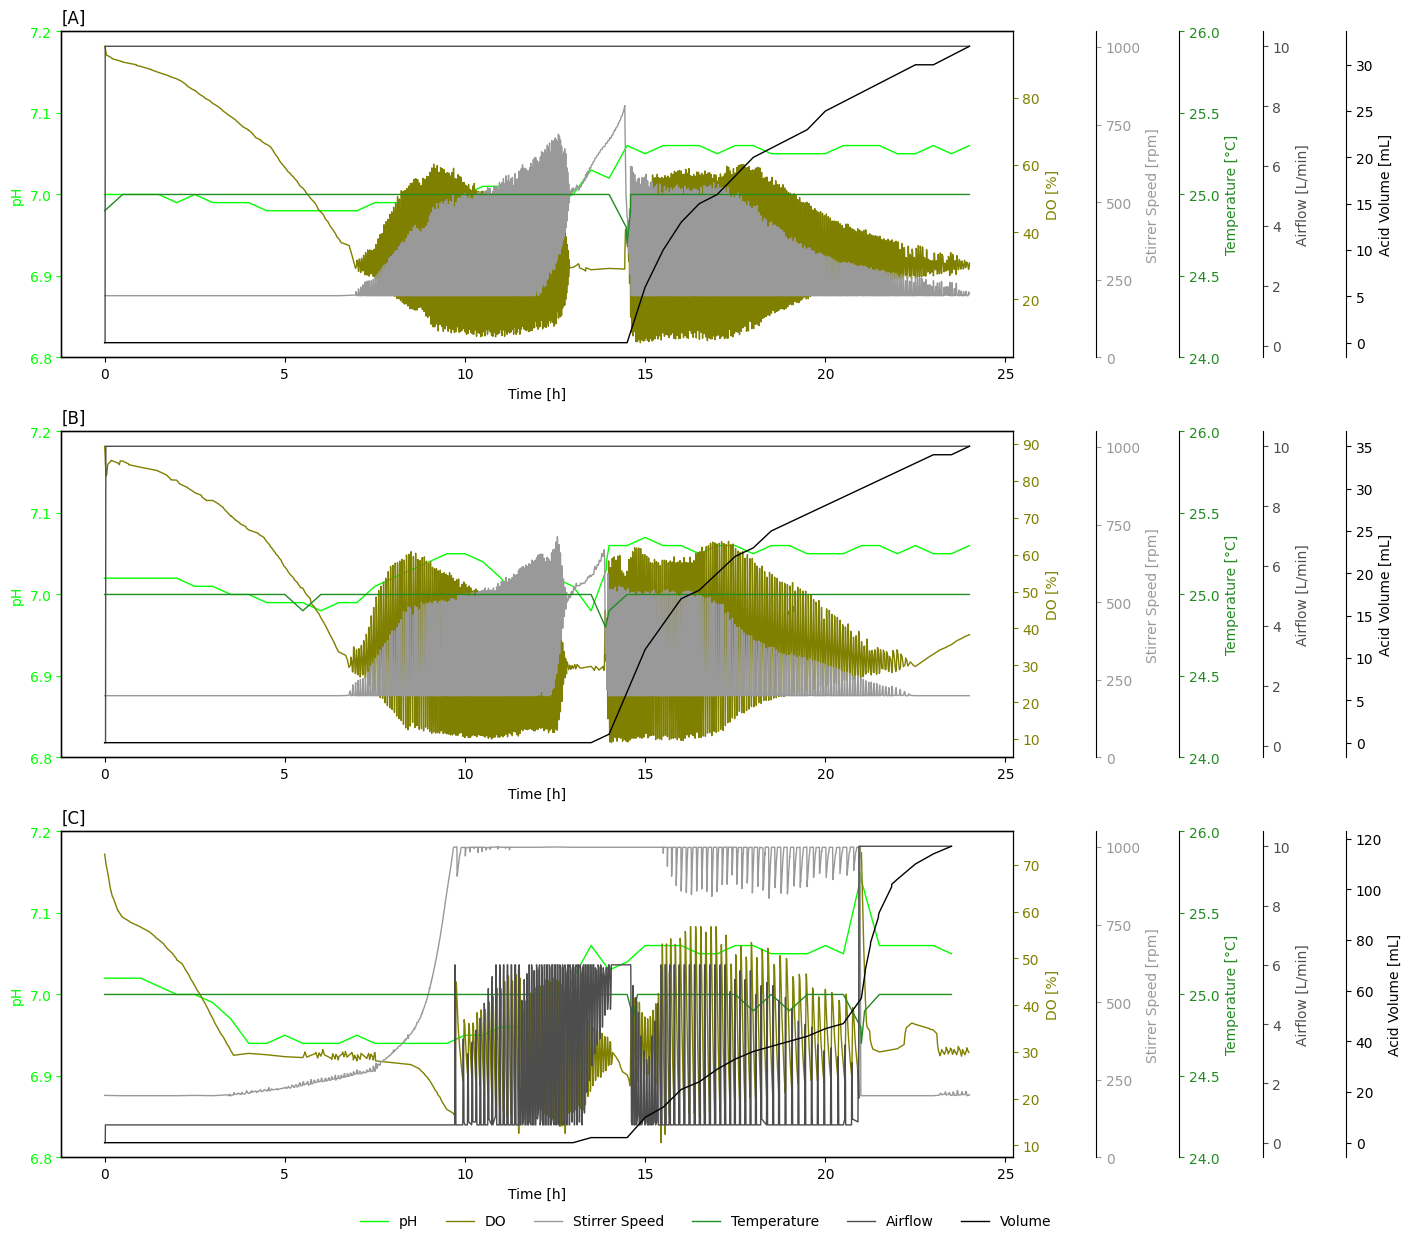

In [7]:
# define stuff & plot
runs = {
    "run 1": run1_dfs,
    "run 2": run2_dfs,
    "run 3": run3_dfs,
}

column_config = {
    "pH_Value": {
        "label": "pH",
        "color": "lime",
        "df_key": "pH",
        "yticks": [6.8, 6.9, 7.0, 7.1, 7.2]
    },
    "pO2_Value": {
        "label": "DO [%]",
        "legend": "DO",
        "color": "olive",
        "df_key": "DO"
    },
    "STIRR_Value": {
        "label": "Stirrer Speed [rpm]",
        "legend": "Stirrer Speed",
        "color": "0.6",
        "df_key": "stirr",
        "ylim": [0, 1050],
        "yticks": [0, 250, 500, 750, 1000]
    },
    "TEMP_Value": {
        "label": "Temperature [°C]",
        "legend": "Temperature",
        "color": "forestgreen",
        "df_key": "temp",
        "yticks": [24.0, 24.5, 25.0, 25.5, 26.0]
    },
    "AIRFL_Value": {
        "label": "Airflow [L/min]",
        "legend": "Airflow",
        "color": "0.3",
        "df_key": "airfl"
    },
    "ACID_Value": {
        "label": "Acid Volume [mL]",
        "legend": "Volume",
        "color": "0.0",
        "df_key": "acid"
    }
}

plot_three_prepared_runs(runs, column_config)